# Simulated Annealing Schedules

Michael Hahsler

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [2]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [3]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [4]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [5]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

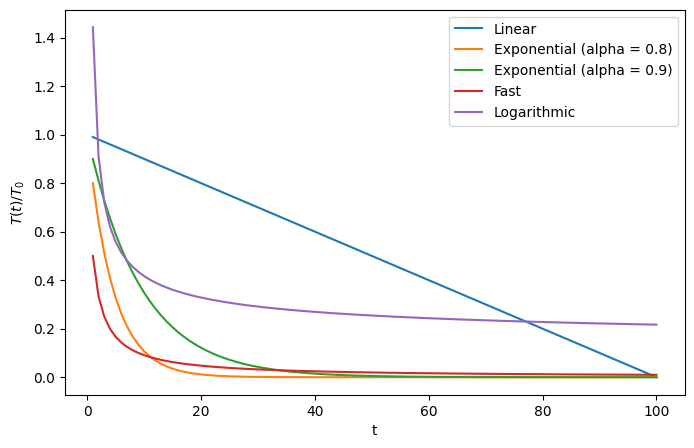

In [6]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)

---
# BÀI 5 (LAB 03) — KHẢO SÁT LỊCH GIẢM NHIỆT ĐỘ

**Nội dung bổ sung cho notebook của Michael Hahsler.** Giữ nguyên các hàm và hình so sánh ở trên; phần dưới thực hiện đúng yêu cầu mục 3, Bài 5 của tài liệu Lab 03.

**Các bước thực hành**

1. So sánh `temperature_exponential`, `temperature_linear`, `temperature_fast`, `temperature_logarithmic` trên chung một khoảng thời gian và hệ số nhiệt độ.
2. Khảo sát lần lượt `alpha`, `eta`, `T0`, tính xác suất chấp nhận một bước làm tăng hàm mục tiêu.
3. Áp dụng cả bốn lịch vào Simulated Annealing của bài toán n-Queens; thực nghiệm lặp lại trên `n=4` và `n=8` với cùng các bàn cờ ban đầu, seed và giới hạn lần đánh giá.
4. Xuất CSV, hình kết quả và nhận xét bằng Markdown.

**Quy ước:** Chỉ sử dụng thời gian `t=1,2,...` trong phần so sánh để lịch logarithmic luôn xác định. Hàm `temperature_logarithmic(t,T0)=T0/ln(1+t)` của notebook gốc **không có giá trị tại t=0**; `T(1)=T0/ln(2)>T0`. Vì thế `T0` là tham số tỷ lệ của công thức, không phải nhiệt độ đúng tại bước `t=1` của lịch này. Không thay đổi công thức của giảng viên.

In [7]:
import math
import time as timer
import pandas as pd
from pathlib import Path

BAI5_SEED = 20261015
OUTPUT_DIR = Path('.')
IMAGE_DIR = OUTPUT_DIR / 'Images'
IMAGE_DIR.mkdir(exist_ok=True)

# Kiểm tra bốn hàm đúng với các công thức của notebook gốc.
assert np.isclose(temperature_exponential(3, 5.0, .8), 5.0*.8**3)
assert np.isclose(temperature_linear(3, 5.0, .5), 3.5)
assert np.isclose(temperature_fast(3, 5.0), 1.25)
assert np.isclose(temperature_logarithmic(1, 5.0), 5.0/np.log(2))
print('Kiểm tra bốn hàm cooling schedule: PASS')

Kiểm tra bốn hàm cooling schedule: PASS


## 5.1. So sánh bốn lịch giảm nhiệt với cùng tham số

Các công thức lấy trực tiếp từ notebook gốc:

- Exponential: $T(t)=T_0\alpha^t$, với $0<\alpha<1$.
- Linear: $T(t)=T_0-\eta t$; khi dùng trong SA sẽ chặn dưới ở $0$ vì nhiệt độ âm không có ý nghĩa.
- Fast: $T(t)=T_0/(1+t)$.
- Logarithmic: $T(t)=T_0/\ln(1+t)$, $t>0$.

Trong hình dưới, đặt chung $T_0=3$, $t=1,\dots,120$. Với exponential chọn $\alpha=0.97$ và linear chọn $\eta=0.025$. Các lịch dùng chung thang thời gian và tham số $T_0$, nhưng không được hiểu là có cùng giá trị nhiệt độ thực tại bước đầu.

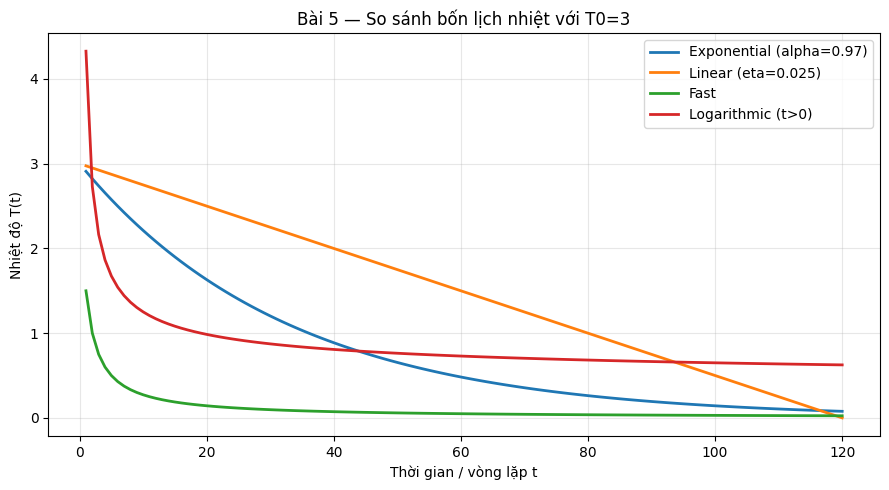

                schedule  T(t=1)  T(t=10)  T(t=50)  T(t=100)  T(t=120)
Exponential (alpha=0.97)  2.9100   2.2123   0.6542    0.1427    0.0776
      Linear (eta=0.025)  2.9750   2.7500   1.7500    0.5000    0.0000
                    Fast  1.5000   0.2727   0.0588    0.0297    0.0248
       Logarithmic (t>0)  4.3281   1.2511   0.7630    0.6500    0.6255


In [8]:
T0_BASE = 3.0
ALPHA_BASE = 0.97
ETA_BASE = 0.025
TIMES = np.arange(1, 121, dtype=int)

curves = {
    'Exponential (alpha=0.97)': temperature_exponential(TIMES, T0_BASE, ALPHA_BASE),
    'Linear (eta=0.025)': temperature_linear(TIMES, T0_BASE, ETA_BASE),
    'Fast': temperature_fast(TIMES, T0_BASE),
    'Logarithmic (t>0)': temperature_logarithmic(TIMES, T0_BASE),
}

fig, ax = plt.subplots(figsize=(9, 5))
for name, y in curves.items():
    ax.plot(TIMES, y, linewidth=2, label=name)
ax.set(xlabel='Thời gian / vòng lặp t', ylabel='Nhiệt độ T(t)',
       title='Bài 5 — So sánh bốn lịch nhiệt với T0=3')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(IMAGE_DIR/'Bai5_Four_Cooling_Schedules.png', dpi=165)
plt.show()

rows = []
for name, values in curves.items():
    rec = {'schedule': name}
    for t in (1, 10, 50, 100, 120):
        rec[f'T(t={t})'] = float(values[t-1])
    rows.append(rec)
df_temperatures = pd.DataFrame(rows)
print(df_temperatures.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
assert np.all(np.isfinite(np.vstack(list(curves.values()))))
# Bảng nhiệt độ so sánh để có thể tái sử dụng trong báo cáo.
df_temperatures.to_csv(OUTPUT_DIR/'Bai5_Temperature_Values.csv', index=False)

## 5.2. Khảo sát ảnh hưởng của `alpha`, `eta` và `T0`

Với công thức mũ, $\alpha$ càng gần $1$ thì nhiệt độ giảm càng chậm. Trong lịch tuyến tính, $\eta$ càng nhỏ thì tốc độ giảm càng chậm. Khi giữ các tham số khác cố định, tăng $T_0$ nâng nhiệt độ và thường kéo dài giai đoạn có khả năng chấp nhận bước xấu. Tuy nhiên, các công thức thuộc các lịch khác nhau không thể so sánh chỉ bằng tên tham số mà cần quan sát $T(t)$.

Khảo sát lần lượt từng tham số trong khi cố định các tham số còn lại (one-factor-at-a-time).

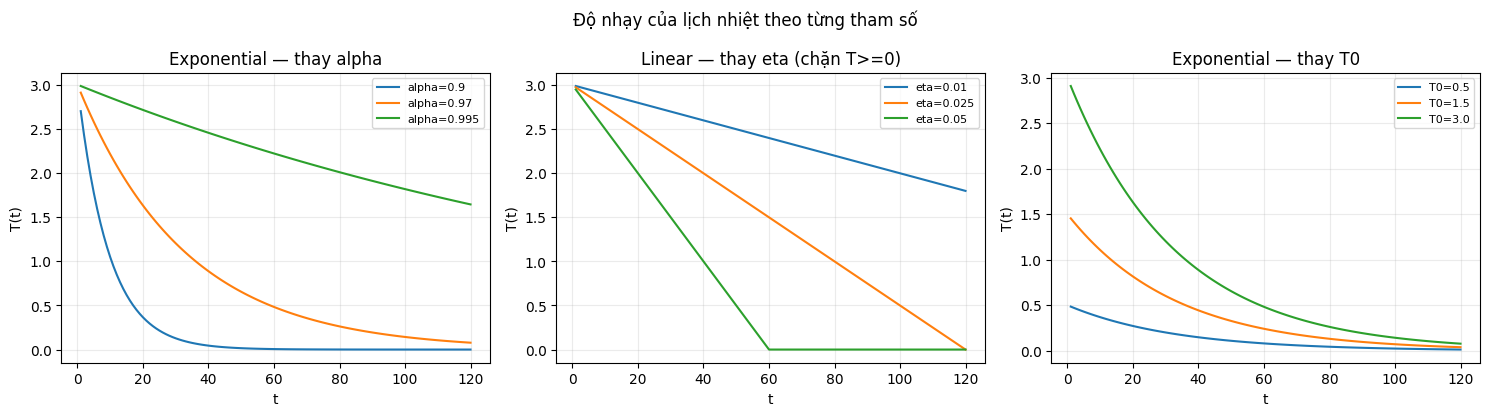

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for alpha in (0.90, 0.97, 0.995):
    axes[0].plot(TIMES, temperature_exponential(TIMES, 3.0, alpha),
                 label=f'alpha={alpha}')
axes[0].set_title('Exponential — thay alpha')

for eta in (0.01, 0.025, 0.05):
    axes[1].plot(TIMES, np.maximum(temperature_linear(TIMES, 3.0, eta), 0.0),
                 label=f'eta={eta}')
axes[1].set_title('Linear — thay eta (chặn T>=0)')

for T0 in (0.5, 1.5, 3.0):
    axes[2].plot(TIMES, temperature_exponential(TIMES, T0, 0.97),
                 label=f'T0={T0}')
axes[2].set_title('Exponential — thay T0')

for ax in axes:
    ax.set_xlabel('t')
    ax.set_ylabel('T(t)')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
fig.suptitle('Độ nhạy của lịch nhiệt theo từng tham số')
fig.tight_layout()
fig.savefig(IMAGE_DIR/'Bai5_Parameter_Sensitivity.png', dpi=165)
plt.show()

## 5.3. Xác suất chấp nhận bước xấu hơn

Đối với bài toán tối thiểu hóa $f$, đặt $\Delta=f_{new}-f_{current}$. Khi $\Delta>0$, xác suất chấp nhận một bước xấu hơn ở nhiệt độ $T$ là

$$P(\text{accept worse})=\exp(-\Delta/T), \quad T>0.$$

Nếu $T\le0$, không chấp nhận bước xấu hơn ($P=0$). Với cùng $\Delta>0$, lịch giữ $T$ cao lâu hơn sẽ có xác suất chấp nhận bước xấu cao hơn lâu hơn, nhưng không nhất thiết đem lại nghiệm cuối tốt hơn trong thời gian hữu hạn.

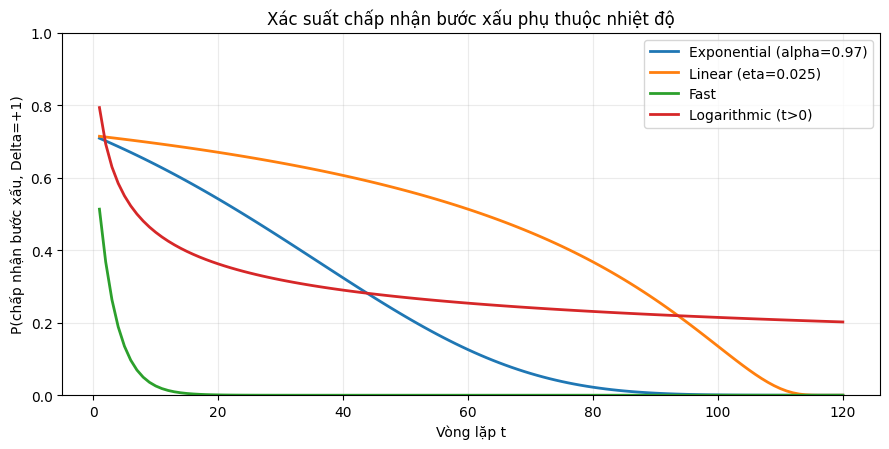

t=  1: Exponential=0.709, Linear=0.715, Fast=0.513, Logarithmic=0.794
t= 20: Exponential=0.542, Linear=0.670, Fast=0.001, Logarithmic=0.362
t= 80: Exponential=0.022, Linear=0.368, Fast=0.000, Logarithmic=0.231
t=120: Exponential=0.000, Linear=0.000, Fast=0.000, Logarithmic=0.202


In [10]:
def acceptance_probability(delta, temperature):
    if delta <= 0:
        return 1.0
    if temperature <= 0:
        return 0.0
    return float(math.exp(-delta / temperature))

fig, ax = plt.subplots(figsize=(9, 4.6))
for name, temp in curves.items():
    ax.plot(TIMES, [acceptance_probability(1, t) for t in temp],
            label=name, linewidth=2)
ax.set(xlabel='Vòng lặp t', ylabel='P(chấp nhận bước xấu, Delta=+1)',
       title='Xác suất chấp nhận bước xấu phụ thuộc nhiệt độ')
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(IMAGE_DIR/'Bai5_Accept_Worse_Probability.png', dpi=165)
plt.show()

for t in (1, 20, 80, 120):
    print(f't={t:>3}: ' + ', '.join(
        f'{name.split(" (")[0]}={acceptance_probability(1, temp[t-1]):.3f}'
        for name, temp in curves.items()
    ))

## 5.4. Thực nghiệm Simulated Annealing trên bài toán n-Queens

Phần này giữ nguyên mô hình n-Queens và cơ chế chọn/chấp nhận lân cận của Task 5 (Bài 4):

- `board[col] = row`, mỗi cột có đúng một quân hậu; số xung đột đếm theo hàng và hai đường chéo.
- Từ trạng thái hiện tại, chọn ngẫu nhiên một cột và một hàng khác trong chính cột đó, rồi tính số cặp xung đột.
- Chấp nhận nước đi có $\Delta\le0$. Nếu $\Delta>0$, chấp nhận với xác suất $\exp(-\Delta/T)$.
- Lưu cả `current_board` và `best_board` vì nghiệm hiện tại có thể xấu hơn nghiệm tốt nhất đã gặp.
- Cố định seed, sử dụng cùng trạng thái đầu và ngân sách tối đa cho mỗi lịch. Dùng $t=iteration+1$ cho **tất cả bốn** lịch để tránh $t=0$ của logarithmic. Điều này làm cho nhiệt độ lượt đầu của exponential khác một chút so với Bài 4 sử dụng $t=0$.

**Độc lập file:** Bài 5 dùng lại logic của Task 5 nhưng tự định nghĩa các hàm cần thiết trong notebook này; không phải import/chạy toàn bộ `n_queens_Bai4_Hoan_thien.ipynb`. Các hàm nhiệt độ ở trên chính là những hàm ban đầu của giảng viên.

In [11]:
def queens_conflicts(board):
    """Đếm số cặp hậu tấn công nhau, cùng logic conflicts() ở Bài 4."""
    board = np.asarray(board, dtype=int)
    n = len(board)
    if n < 2 or np.any((board < 0) | (board >= n)):
        raise ValueError('board must have >=2 columns and valid row indices')
    cols = np.arange(n)
    row_counts = np.bincount(board, minlength=n)
    diag_a = np.bincount(cols + board, minlength=2*n-1)
    diag_b = np.bincount(cols - board + n - 1, minlength=2*n-1)
    return int(sum(np.sum(counts*(counts-1)//2)
                   for counts in (row_counts, diag_a, diag_b)))


def cooling_temperature(kind, t, T0, alpha=0.995, eta=0.002):
    """t >= 1, trả về nhiệt độ KHÔNG ÂM để dùng trong xác suất SA."""
    if t <= 0 or T0 <= 0:
        raise ValueError('t must be >0; T0 must be >0')
    if kind == 'Exponential':
        if not (0 < alpha < 1):
            raise ValueError('alpha must satisfy 0<alpha<1')
        T = temperature_exponential(t, T0, alpha)
    elif kind == 'Linear':
        if eta <= 0:
            raise ValueError('eta must be positive')
        T = temperature_linear(t, T0, eta)
    elif kind == 'Fast':
        T = temperature_fast(t, T0)
    elif kind == 'Logarithmic':
        T = temperature_logarithmic(t, T0)
    else:
        raise ValueError('Unknown schedule: ' + str(kind))
    return max(0.0, float(T))


def sa_queens_with_schedule(initial_board, kind, seed=0, T0=3.0,
                            alpha=0.995, eta=0.002, max_iter=1500):
    """So sánh lịch nhiệt, cơ chế SA tương tự Task 5 ở Bài 4."""
    if max_iter < 0:
        raise ValueError('max_iter must be nonnegative')
    rng = np.random.default_rng(seed)
    start = timer.perf_counter()
    initial = np.asarray(initial_board, dtype=int).copy()
    n = len(initial)
    if n < 2:
        raise ValueError('n >= 2 is required')
    current = initial.copy()
    current_f = queens_conflicts(current)
    best = current.copy()
    best_f = current_f
    count_evaluations = 1
    accepted_better = accepted_equal = accepted_worse = 0
    history_current = [current_f]
    history_best = [best_f]
    history_temperature = []
    iters = 0

    for iteration in range(max_iter):
        if best_f == 0:
            break
        T = cooling_temperature(kind, iteration+1, T0, alpha, eta)
        col = int(rng.integers(n))
        old_row = int(current[col])
        offset = int(rng.integers(n-1))
        new_row = offset if offset < old_row else offset+1
        candidate = current.copy()
        candidate[col] = new_row
        f_candidate = queens_conflicts(candidate)
        count_evaluations += 1
        delta = f_candidate-current_f
        if delta <= 0 or rng.random() < acceptance_probability(delta, T):
            if delta < 0:
                accepted_better += 1
            elif delta == 0:
                accepted_equal += 1
            else:
                accepted_worse += 1
            current = candidate
            current_f = f_candidate
            if current_f < best_f:
                best, best_f = current.copy(), current_f
        iters += 1
        history_current.append(current_f)
        history_best.append(best_f)
        history_temperature.append(T)

    return {
        'schedule':kind, 'success':best_f==0, 'best_f':int(best_f),
        'final_current_f':int(current_f), 'initial_f':int(history_current[0]),
        'iterations':iters, 'evaluations':count_evaluations,
        'accepted_worse':accepted_worse, 'accepted_better':accepted_better,
        'accepted_equal':accepted_equal, 'best_board':best,
        'final_board':current.copy(), 'initial_board':initial,
        'history_best':history_best, 'history_current':history_current,
        'temperature_history':history_temperature,
        'elapsed_ms':(timer.perf_counter()-start)*1000,
        'status':'SOLVED' if best_f==0 else 'ITERATION_LIMIT',
    }

# Kiểm tra hàm xung đột bằng trường hợp có nghiệm và cách đếm cặp độc lập.
assert queens_conflicts([1,3,0,2]) == 0
assert queens_conflicts([0,0,0,0]) == 6

def conflict_pairwise(board):
    return sum(int(board[i]==board[j] or abs(board[i]-board[j])==abs(i-j))
               for i in range(len(board)) for j in range(i+1,len(board)))
rng_check = np.random.default_rng(31224)
for n in (4,8):
    for _ in range(30):
        board = rng_check.integers(0, n, n)
        assert queens_conflicts(board) == conflict_pairwise(board)
print('Kiểm tra objective n-Queens: PASS')

Kiểm tra objective n-Queens: PASS


## 5.5. Đối chiếu kết quả bốn lịch trên $n=4$ và $n=8$

Mỗi lịch được chạy 20 lần/giá trị `n`. Trong cùng một trial, bốn lịch có **cùng bàn cờ ban đầu và cùng random seed**. Sử dụng $T_0=3$, `alpha=0.995`, `eta=0.002`, ngân sách tối đa `max_iter=1500` (mỗi lần thử một láng giềng). Các giá trị `alpha`, `eta` dùng để định nghĩa hai lịch tương ứng, không ảnh hưởng Fast/Logarithmic. Thành công khi `best_f=0`; nếu chưa thành công khi chạm ngân sách, ghi `ITERATION_LIMIT`.

Thời gian (ms) là đo trên môi trường thực thi hiện tại, không xem là định luật chung về tốc độ; đây là số đo một lần cho mỗi thử nghiệm.

In [12]:
SA_KINDS = ('Exponential', 'Linear', 'Fast', 'Logarithmic')
N_TRIALS = 20
SA_MAX_ITER = 1500
SA_T0 = 3.0
SA_ALPHA = 0.995
SA_ETA = 0.002
trial_rows = []
examples = {}

for n in (4,8):
    for trial in range(N_TRIALS):
        board_rng = np.random.default_rng(BAI5_SEED + n*1000 + trial)
        initial = board_rng.integers(0, n, size=n)
        for kind in SA_KINDS:
            result = sa_queens_with_schedule(
                initial, kind, seed=BAI5_SEED + 20000*n + trial,
                T0=SA_T0, alpha=SA_ALPHA, eta=SA_ETA,
                max_iter=SA_MAX_ITER,
            )
            if (n,trial,kind)==(8,0,kind):
                examples[kind]=result
            assert result['evaluations'] == result['iterations'] + 1
            assert result['best_f'] <= result['final_current_f']
            assert result['best_f'] <= result['initial_f']
            assert result['best_f']==queens_conflicts(result['best_board'])
            assert len(result['history_best'])==result['iterations']+1
            assert np.all(np.diff(result['history_best'])<=0)
            trial_rows.append({
                'n':n, 'trial':trial, 'schedule':kind,
                'seed_board':BAI5_SEED+n*1000+trial,
                'seed_search':BAI5_SEED+20000*n+trial,
                'initial_board':','.join(map(str,initial)),
                'initial_f':result['initial_f'],
                'success':int(result['success']),
                'best_f':result['best_f'],
                'final_current_f':result['final_current_f'],
                'iterations':result['iterations'],
                'evaluations':result['evaluations'],
                'accepted_worse':result['accepted_worse'],
                'elapsed_ms':result['elapsed_ms'],
                'status':result['status'],
            })

df_trials = pd.DataFrame(trial_rows)
df_summary = (df_trials.groupby(['n','schedule'],sort=False)
              .agg(trials=('trial','size'), success_rate=('success','mean'),
                   avg_best_f=('best_f','mean'), avg_iterations=('iterations','mean'),
                   avg_evaluations=('evaluations','mean'),
                   avg_accepted_worse=('accepted_worse','mean'),
                   avg_elapsed_ms=('elapsed_ms','mean')).reset_index())
df_summary['success_rate_percent'] = 100*df_summary['success_rate']
print(df_summary[['n','schedule','trials','success_rate_percent','avg_best_f',
                  'avg_iterations','avg_accepted_worse','avg_elapsed_ms']]
      .round(2).to_string(index=False))
assert len(df_trials)==2*N_TRIALS*len(SA_KINDS)
df_trials.to_csv(OUTPUT_DIR/'Bai5_SA_Trials.csv', index=False)
df_summary.to_csv(OUTPUT_DIR/'Bai5_SA_Summary.csv', index=False)

 n    schedule  trials  success_rate_percent  avg_best_f  avg_iterations  avg_accepted_worse  avg_elapsed_ms
 4 Exponential      20                 100.0        0.00           97.55               20.90            2.42
 4      Linear      20                 100.0        0.00           68.55               18.70            1.70
 4        Fast      20                 100.0        0.00           45.05                0.70            1.18
 4 Logarithmic      20                 100.0        0.00           62.70                8.05            1.67
 8 Exponential      20                  75.0        0.25          942.05               62.70           23.85
 8      Linear      20                  55.0        0.45         1265.35              225.15           32.04
 8        Fast      20                  90.0        0.10          421.00                0.55           10.38
 8 Logarithmic      20                  85.0        0.15          769.65               39.40           20.16


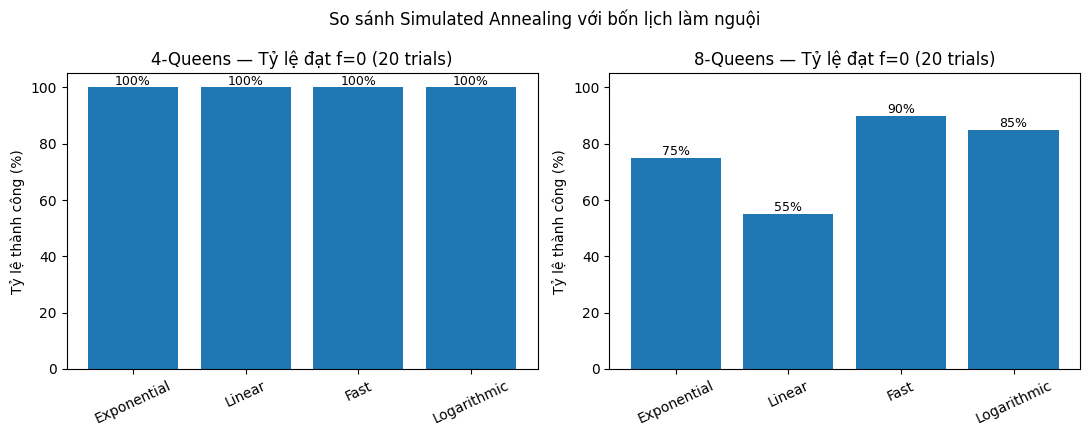

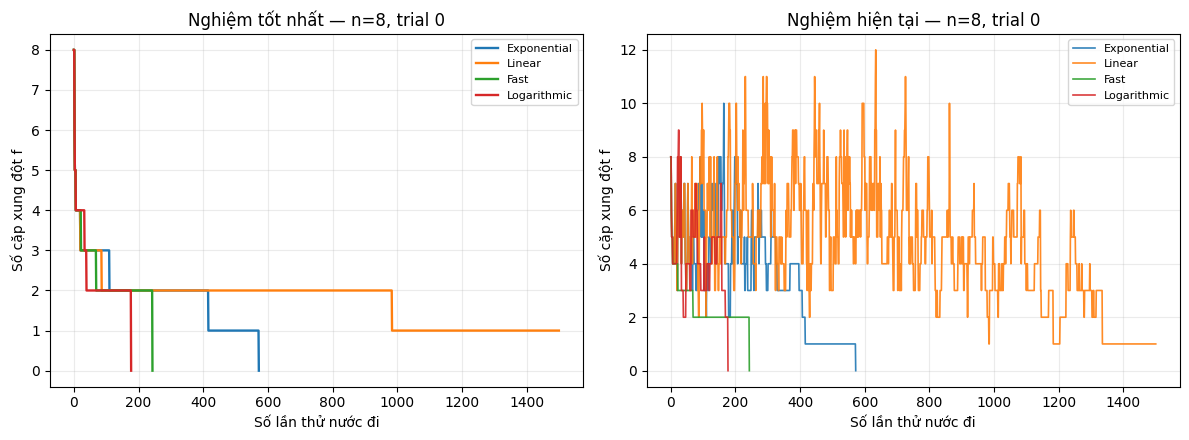

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11,4.4))
for ax,n in zip(axes, (4,8)):
    subset=df_summary[df_summary['n']==n]
    bars=ax.bar(subset['schedule'],subset['success_rate_percent'])
    ax.set_ylim(0,105)
    ax.set_title(f'{n}-Queens — Tỷ lệ đạt f=0 (20 trials)')
    ax.set_ylabel('Tỷ lệ thành công (%)')
    ax.tick_params(axis='x', rotation=25)
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
                f'{bar.get_height():.0f}%', ha='center', fontsize=9)
fig.suptitle('So sánh Simulated Annealing với bốn lịch làm nguội')
fig.tight_layout()
fig.savefig(IMAGE_DIR/'Bai5_SA_Success_Rates.png',dpi=165)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
for kind,result in examples.items():
    axes[0].plot(result['history_best'],label=kind,linewidth=1.7)
    axes[1].plot(result['history_current'],label=kind,linewidth=1.2,alpha=.9)
axes[0].set_title('Nghiệm tốt nhất — n=8, trial 0')
axes[1].set_title('Nghiệm hiện tại — n=8, trial 0')
for ax in axes:
    ax.set(xlabel='Số lần thử nước đi',ylabel='Số cặp xung đột f')
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(IMAGE_DIR/'Bai5_SA_Convergence.png',dpi=165)
plt.show()

## 5.6. Kiểm tra độ nhạy của Simulated Annealing theo các tham số

Bên cạnh việc xem đường $T(t)$, chạy lặp lại một số cấu hình SA trên `n=8`. Với Exponential thay `alpha` và `T0`; với Linear thay `eta` và `T0`. Mỗi cấu hình chạy 8 lần và cùng ngân sách 1.500 nước đi. Đây là thí nghiệm bổ sung để xem mối liên hệ giữa nhiệt độ, bước xấu được chấp nhận và chất lượng nghiệm.

In [14]:
SENSITIVITY_CONFIGS = (
    [('Exponential',t0,a,None) for t0 in (.5,3.0) for a in (.97,.995)]
    + [('Linear',t0,None,e) for t0 in (.5,3.0) for e in (.002,.006)]
)
sensitivity_rows=[]
for kind,t0,a,e in SENSITIVITY_CONFIGS:
    for trial in range(8):
        board = np.random.default_rng(BAI5_SEED+88000+trial).integers(0,8,size=8)
        kwargs = {'T0':t0,'max_iter':SA_MAX_ITER,
                  'seed':BAI5_SEED+99000+trial}
        if a is not None: kwargs['alpha']=a
        if e is not None: kwargs['eta']=e
        r = sa_queens_with_schedule(board,kind,**kwargs)
        sensitivity_rows.append({
            'schedule':kind, 'T0':t0, 'alpha':a, 'eta':e,
            'trial':trial, 'success':int(r['success']),
            'best_f':r['best_f'], 'accepted_worse':r['accepted_worse'],
            'iterations':r['iterations'],'elapsed_ms':r['elapsed_ms'],
        })
df_sensitivity_trials=pd.DataFrame(sensitivity_rows)
df_sensitivity_summary=(df_sensitivity_trials
  .groupby(['schedule','T0','alpha','eta'],dropna=False,sort=False)
  .agg(trials=('trial','size'),success_rate=('success','mean'),
       avg_best_f=('best_f','mean'),avg_accepted_worse=('accepted_worse','mean'),
       avg_elapsed_ms=('elapsed_ms','mean')).reset_index())
print(df_sensitivity_summary.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
df_sensitivity_trials.to_csv(OUTPUT_DIR/'Bai5_Parameter_Trials.csv',index=False)
df_sensitivity_summary.to_csv(OUTPUT_DIR/'Bai5_Parameter_Summary.csv',index=False)

   schedule     T0  alpha    eta  trials  success_rate  avg_best_f  avg_accepted_worse  avg_elapsed_ms
Exponential 0.5000 0.9700    NaN       8        0.8750      0.1250              0.6250         18.1040
Exponential 0.5000 0.9950    NaN       8        0.8750      0.1250              2.8750         13.9347
Exponential 3.0000 0.9700    NaN       8        0.7500      0.2500             10.5000         18.2227
Exponential 3.0000 0.9950    NaN       8        0.6250      0.3750             64.0000         24.7668
     Linear 0.5000    NaN 0.0020       8        0.7500      0.2500              2.7500         17.3337
     Linear 0.5000    NaN 0.0060       8        0.8750      0.1250              0.8750         14.1815
     Linear 3.0000    NaN 0.0020       8        0.5000      0.5000            250.0000         32.4068
     Linear 3.0000    NaN 0.0060       8        0.7500      0.2500             86.5000         19.9033


## 5.7. Nhận xét và kết luận Bài 5

**Về bản đồ nhiệt:** Linear giảm đều và cần chặn ở 0 nếu công thức đi sang giá trị âm. Exponential giảm theo hàm mũ; giá trị `alpha` lớn làm nguội chậm. Fast giảm nhanh theo $1/(1+t)$. Logarithmic giảm rất chậm ở những vòng lặp lớn, song tại $t=1$ nhiệt độ của lịch này lớn hơn tham số $T_0$ do có $\ln 2$ ở mẫu. So sánh độ chậm phải dựa trên nhiệt độ tại từng thời điểm, không chỉ so công thức hoặc $T_0$.

**Về khả năng chấp nhận bước xấu:** Với $\Delta>0$, khi $T$ lớn hơn thì $e^{-\Delta/T}$ lớn hơn. Vì vậy lịch giữ nhiệt độ cao lâu hơn duy trì khả năng thoát bẫy cực trị cục bộ lâu hơn. Điều này không bảo đảm tỷ lệ thành công cao hơn trong số vòng lặp hữu hạn: nhiệt độ quá cao có thể làm quá trình tìm kiếm dao động lâu, còn làm nguội quá nhanh có thể mắc kẹt.

**Về dữ liệu n-Queens:** Các bảng `Bai5_SA_Trials.csv` và `Bai5_SA_Summary.csv` ghi nhận thực nghiệm trên `n=4,8` với cùng bảng khởi đầu, seed và ngân sách. `success_rate` là tỷ lệ thực nghiệm đạt `best_f=0`, còn `avg_elapsed_ms` là thời gian đo trong máy đang chạy. Cần đọc bảng CSV để trích chính xác các con số khi đưa vào báo cáo, không mặc định một lịch luôn tốt nhất cho mọi n. `Bai5_Parameter_Summary.csv` giúp tách ảnh hưởng của các tham số `alpha`, `eta`, `T0`.

**Kết luận:** Lịch nhiệt không chỉ thay đổi xác suất chấp nhận bước xấu mà còn thay đổi quá trình hội tụ và mức công sức tính toán. Việc chọn lịch thích hợp nên dựa trên tỷ lệ thành công, chất lượng nghiệm, thời gian và số lần thử cùng một ngân sách thực nghiệm, không chỉ dựa vào tốc độ giảm của đường $T(t)$.### Nhận xét dựa trên số liệu thực nghiệm đã chạy

- Với cùng $T_0=3$, $\alpha=0.995$, $\eta=0.002$, ngân sách 1.500 lần thử và 20 seed cho mỗi cỡ bàn cờ, cả bốn lịch đạt 100% trên $n=4$. Trên $n=8$, tỷ lệ thành công lần lượt là **75% (Exponential), 55% (Linear), 90% (Fast), 85% (Logarithmic)**; các giá trị xung đột trung bình tốt nhất lần lượt là 0.25, 0.45, 0.10 và 0.15.
- Trên $n=8$, trung bình số bước xấu được chấp nhận là **62.70 (Exponential), 225.15 (Linear), 0.55 (Fast), 39.40 (Logarithmic)**. Lịch Linear giữ khả năng chấp nhận nước đi xấu tương đối lâu trong cấu hình thử nghiệm này nhưng đạt tỷ lệ thành công thấp nhất. Tăng khả năng khám phá không tự động nâng chất lượng nghiệm trong cùng số bước.
- Khảo sát độ nhạy cho thấy khi $T_0=3$, lịch mũ $\alpha=0.97$ chấp nhận trung bình 10.50 bước xấu, còn $\alpha=0.995$ chấp nhận 64.00 bước xấu trên 8 lần chạy. Với Linear, giảm $\eta$ từ 0.006 xuống 0.002 cũng làm tăng đáng kể số bước xấu được chấp nhận. Đây là mô tả thực nghiệm trên một tập seed, không phải quan hệ bảo đảm cho mọi bài toán.

**Lưu ý khi báo cáo:** các thống kê trên được đo trong đúng cài đặt notebook, thời gian đo thay đổi tùy phần cứng. Nếu thay seed, ngân sách hoặc tham số, phải chạy lại để cập nhật bảng và nhận xét.